# Example 4 — Moist LBM (El Niño SST → interactive convection)

This runs the **interactive-moisture** version of PyLBM-Isca. Unlike the dry
examples, the heating is **not prescribed**: it is generated internally by a
**linearised convective adjustment** (Betts–Miller / Neelin–Yu 1994) plus a
**linear large-scale-condensation** scheme, and the model is forced only by a
prescribed **SST anomaly** through linearised surface bulk fluxes
(Watanabe–Kimoto moist LBM; User's Guide §7, Appendix A.4).

The perturbation system is

$$ \partial_t X + (L - F_i)\,X = F_e(T_s') , $$

with $F_i(X)$ the internal convection + condensation feedback (a function of
$T',q'$) and $F_e$ the SST-anomaly surface flux. Here we impose a composite
**El Niño** SST anomaly and look at the tropical/extratropical response.

## 1. Set up the model (T42 L20, Isca/GFDL core)

In [1]:
# --- locate the PyLBM-Isca package -----------------------------------------
import os, sys
import numpy as np

root = os.path.abspath("")
while root != os.path.dirname(root):
    if os.path.isdir(os.path.join(root, "pylbm_isca")):
        break
    root = os.path.dirname(root)
sys.path.insert(0, root)
DATA = os.path.join(root, "data")

from pylbm_isca import (Config, LBM, Spectral, VerticalGrid, MoistPhysics,
                        MoistParams, asnumpy, gpu_available)
from pylbm_isca.basicstate import (load_basic_state, load_moist_surface,
                                   load_sst_anomaly)

DEVICE = "gpu" if gpu_available() else "cpu"
sp = Spectral(device=DEVICE)
vg = VerticalGrid(device=DEVICE)
lon, lat, sig = asnumpy(sp.lon_deg), asnumpy(sp.lat_deg), asnumpy(vg.sig)
print(f"PyLBM-Isca  T{sp.nmax}  {sp.nlon}x{sp.nlat}  L{vg.kmax}  backend={DEVICE}")

PyLBM-Isca  T42  128x64  L20  backend=gpu


## 2. Basic state and boundary data (NetCDF)

Everything the moist model needs comes from the NetCDF inputs in `data/`:

| file | field | role |
|------|-------|------|
| `ncep.clim.t42.nc` | u, v, T, q, Z | atmospheric basic state (NCEP JFM climatology) |
| `sst.clim.t42.nc` | SST | mean sea-surface temperature for the surface flux |
| `wg.clim.t42.nc` | Wg | soil wetness (evaporation efficiency) |
| `frcsst.nino.t21.nc` | SST′ | prescribed **El Niño** SST anomaly (regridded T21→T42) |

In [2]:
bs = load_basic_state(os.path.join(DATA, "ncep.clim.t42.nc"),
                      sp, vg, kmo=1, navg=3)          # JFM, 3-month mean
bs.summary()

# mean SST / soil wetness for the surface-flux basic state (boreal winter)
sst_mean, wg_mean = load_moist_surface(os.path.join(DATA, "sst.clim.t42.nc"),
                                       os.path.join(DATA, "wg.clim.t42.nc"), sp)
# prescribed El Nino SST anomaly, regridded to the model grid
sst_anom = load_sst_anomaly(os.path.join(DATA, "frcsst.nino.t21.nc"), sp)
print(f"mean SST  {sst_mean.min():.1f}–{sst_mean.max():.1f} K   "
      f"Wg {wg_mean.min():.2f}–{wg_mean.max():.2f}   "
      f"SST anomaly |max| {np.abs(sst_anom).max():.2f} K")

basic state from /home/kaichiht/Colab/Research_Tool/LBM_isca/data/ncep.clim.t42.nc
  grid 64 lat x 128 lon x 20 sigma levels
  u   min    -33.7339  max     68.6404  mean      5.5307   [m/s]
  v   min    -28.6447  max     30.6575  mean      0.0313   [m/s]
  t   min    191.3631  max    307.1239  mean    242.1534   [K]
  q   min     -0.0001  max      0.0246  mean      0.0019   [kg/kg]
  ps  min    983.7729  max   1032.6045  mean   1010.6346   [hPa]
mean SST  224.3–306.4 K   Wg 0.00–1.00   SST anomaly |max| 3.63 K


## 3. Moist physics and integration

`MoistPhysics` builds all the stratification-dependent coefficients once (Louis
bulk coefficients, convective reference profiles, LSC weights). We use a 6-hour
convective relaxation time and turn the wind–evaporation feedback off
(`owes=False`) so the response is driven purely by the imposed SST anomaly.
The convective/condensation heating is recomputed from the state every step.

In [3]:
mp = MoistPhysics(vg, bs, sst=sst_mean, wg=wg_mean,
                  params=MoistParams(ttau0=6, qtau0=6, ttauc=12, owes=False),
                  device=DEVICE)

dd = [15.0] * vg.kmax                               # uniform 15-day Rayleigh drag
m = LBM(bs, sp, vg, Config(ndays=10.0, device=DEVICE,
                           ddragv=dd, ddragd=dd, ddragt=dd))
m.run(moist=mp, sst_anom=sst_anom, verbose=True, progress_every=144)

md_ = m._moist_diag                                 # last-step moist diagnostics
q1 = asnumpy(md_["q1c"] + md_["q1l"]) * 86400.0     # total heat source [K/day]
pr = asnumpy(md_["pr"])                             # precipitation [mm/day]
diag = m.diagnostics()
u = asnumpy(diag["u"]); v = asnumpy(diag["v"])
z = asnumpy(diag["z"]); psi = asnumpy(diag["psi"])
print(f"response: |u|max {np.abs(u).max():.1f} m/s   "
      f"Q1 |max| {np.abs(q1).max():.1f} K/day   precip max {pr.max():.1f} mm/day")

  backend: gpu


  day   2.00  |u|max  27.565  |T|max  6.974  |ps|max  9.2912   [  1.6s]


  day   4.00  |u|max  57.939  |T|max  8.832  |ps|max 17.1548   [  3.0s]


  day   6.00  |u|max  66.135  |T|max 10.135  |ps|max 22.0893   [  4.3s]


  day   8.00  |u|max  66.642  |T|max 10.399  |ps|max 21.6037   [  5.7s]


  day  10.00  |u|max  65.604  |T|max  9.941  |ps|max 20.6642   [  7.1s]


  done: 720 steps, 7.1s
response: |u|max 65.6 m/s   Q1 |max| 48.4 K/day   precip max 74.3 mm/day


## 4. The El Niño response

Top: the internally generated **column heating** $Q_1$ and the **precipitation**
— the convective response sits over the warm SST anomaly in the central/east
Pacific. Bottom: the **850-hPa streamfunction** and the **500-hPa height**
anomaly, showing the equatorial Gill-like circulation plus the arching
extratropical wave train into the North Pacific / North America.

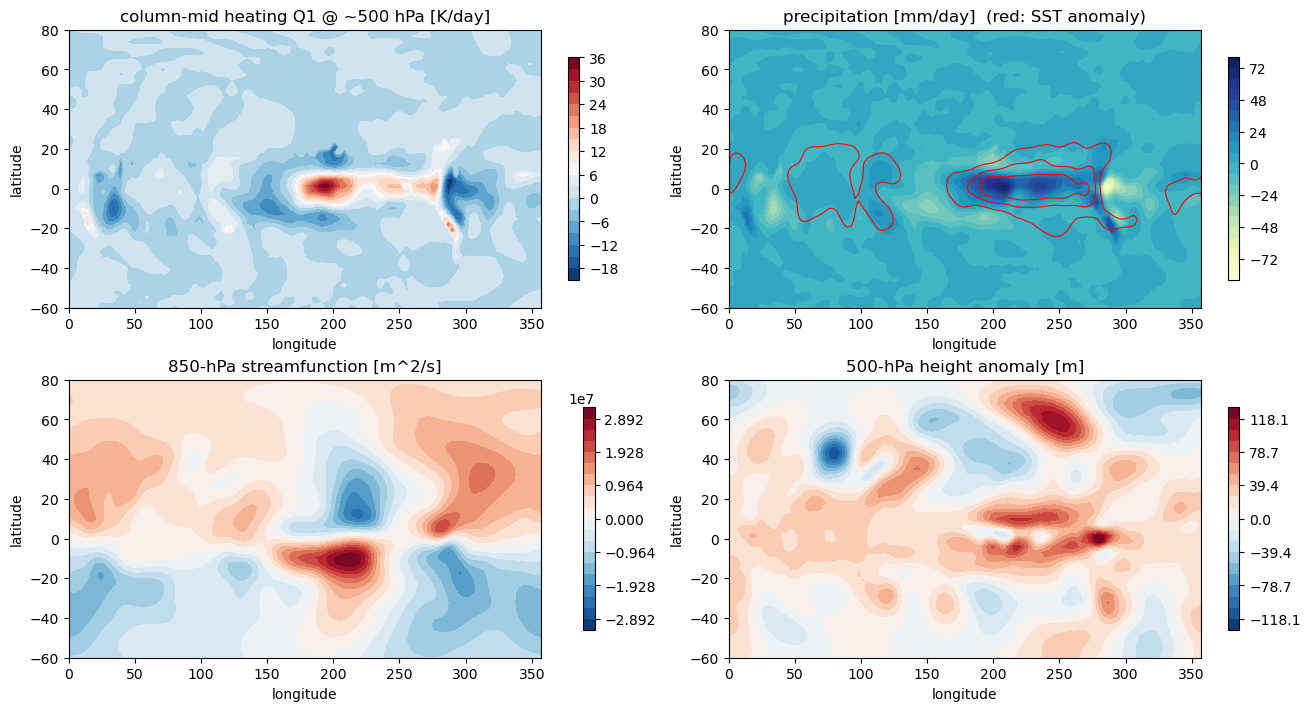

In [4]:
import matplotlib.pyplot as plt

k850 = int(np.argmin(np.abs(sig - 0.85)))
k500 = int(np.argmin(np.abs(sig - 0.50)))
Lon, Lat = np.meshgrid(lon, lat)

fig, ax = plt.subplots(2, 2, figsize=(13, 7), constrained_layout=True)

c = ax[0, 0].contourf(Lon, Lat, q1[:, :, k500], levels=21, cmap="RdBu_r")
ax[0, 0].set_title("column-mid heating Q1 @ ~500 hPa [K/day]")
fig.colorbar(c, ax=ax[0, 0], shrink=0.8)

c = ax[0, 1].contourf(Lon, Lat, pr, levels=21, cmap="YlGnBu")
ax[0, 1].contour(Lon, Lat, sst_anom, levels=[0.5, 1.5, 2.5], colors="r",
                 linewidths=0.8)
ax[0, 1].set_title("precipitation [mm/day]  (red: SST anomaly)")
fig.colorbar(c, ax=ax[0, 1], shrink=0.8)

m850 = np.abs(psi[:, :, k850]).max()
c = ax[1, 0].contourf(Lon, Lat, psi[:, :, k850], levels=np.linspace(-m850, m850, 21),
                      cmap="RdBu_r")
ax[1, 0].set_title("850-hPa streamfunction [m^2/s]")
fig.colorbar(c, ax=ax[1, 0], shrink=0.8)

mz = np.abs(z[:, :, k500]).max()
c = ax[1, 1].contourf(Lon, Lat, z[:, :, k500], levels=np.linspace(-mz, mz, 21),
                      cmap="RdBu_r")
ax[1, 1].set_title("500-hPa height anomaly [m]")
fig.colorbar(c, ax=ax[1, 1], shrink=0.8)

for a in ax.ravel():
    a.set_xlabel("longitude"); a.set_ylabel("latitude"); a.set_ylim(-60, 80)
plt.show()

**Takeaway.** The moist LBM turns a prescribed **SST anomaly** into a
self-consistent heating and circulation response — the convective heating is an
output, not an input. This is the key difference from the dry examples, where
the heating has to be prescribed by hand.

To run the same experiment from the command line:

```bash
python run_lbm.py --basic-state data/ncep.clim.t42.nc --moist \
    --days 10 --out out/isca.moist.elnino --netcdf
```
